In [1]:
import numpy as np
import matplotlib

from scipy.integrate import solve_ivp
from matplotlib import pyplot as plt

In [92]:
#Set plotting look and feel

host_color = matplotlib.colors.to_rgb('#a8cee3')
path_color = matplotlib.colors.to_rgb('#ef777b')
cure_color = matplotlib.colors.to_rgb('#b2d987')

s_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", host_color])
i_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", path_color])

matplotlib.rcParams['figure.dpi'] = 600
matplotlib.rcParams['text.usetex'] = True

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'Helvetica'
})

In [11]:
class TempModel:

    def __init__(self, **kwargs):
        self.K = 2000
        self.fec_max = 2 / 365
        self.beta_max = 1 / 365
        self.mu = 0.2 * self.fec_max

        self.res1 = 1
        self.res2 = 0.25

        self.cost1 = 1
        self.cost2 = 0.95

        self.fec_threshold = 15
        self.trans_threshold = 15
        self.cure_threshold = 27.5

        self.cure_rate = 1      #Emme's rate: 0.8/365
        self.uncure_rate = 1    #Emme's rate: 0.8/365

        self.temp_min = 5
        self.temp_max = 30

        self.S1 = self.K*0.9
        self.S2 = 0
        self.I1 = self.K*0.1
        self.I2 = 0
        self.C1 = 0
        self.C2 = 0

        self.n_years = 150
        self.N = 0
        self.t = 0

        for key, value in kwargs.items():
            setattr(self, key, value)

        self.temp_scale = self.temp_max - self.temp_min

    def temp(self, t):
        t = t * (2*np.pi / 365) - np.pi

        temp = (np.cos(t) + 1) / 2
        temp = temp * self.temp_scale
        temp = temp + self.temp_min

        return temp
    
    def births(self, temp, steepness = 10):
        b = self.fec_max / (1 + np.exp(-steepness*(temp - self.fec_threshold)))

        return b
    
    def beta(self, temp, steepness = 10):
        beta = self.beta_max / (1 + np.exp(-steepness*(temp - self.trans_threshold)))

        return beta
    
    def cure(self, temp, steepness = 10):
        rate = self.cure_rate / (1 + np.exp(-steepness*(temp - self.cure_threshold)))

        return rate

    def uncure(self, temp, steepness = 10):
        rate = self.uncure_rate / (1 + np.exp(-steepness*(temp - self.cure_threshold)))

        return 1 - rate
    
    def solve(self):
        X_0 = (self.S1, self.S2, self.I1, self.I2, self.C1, self.C2)

        def df(t, X):
            S1 = X[0]
            S2 = X[1]
            I1 = X[2]
            I2 = X[3]
            C1 = X[4]
            C2 = X[5]

            N = np.sum(X)

            temp = self.temp(t)

            dS1 = (S1+C1)*(self.births(temp)*self.cost1)*(1 - N/self.K) - S1*(self.res1*self.beta(temp)*(I1+I2)/N + self.mu)
            dS2 = (S2+C2)*(self.births(temp)*self.cost2)*(1 - N/self.K) - S2*(self.res2*self.beta(temp)*(I1+I2)/N + self.mu)

            dI1 = S1*self.res1*self.beta(temp)*(I1+I2)/N + C1*self.uncure(temp) - I1*(self.cure(temp) + self.mu)
            dI2 = S2*self.res2*self.beta(temp)*(I1+I2)/N + C2*self.uncure(temp) - I2*(self.cure(temp) + self.mu)

            dC1 = I1*self.cure(temp) - C1*(self.uncure(temp) + self.mu)
            dC2 = I2*self.cure(temp) - C2*(self.uncure(temp) + self.mu)

            return np.array((dS1, dS2, dI1, dI2, dC1, dC2))

        def df_vir(t, X):
            S1 = X[0]
            S2 = X[1]
            I1 = X[2]
            I2 = X[3]
            C1 = X[4]
            C2 = X[5]

            N = np.sum(X)

            temp = self.temp(t)

            dS1 = (S1+C1)*(self.births(temp)*self.cost1)*(1 - N/self.K) - S1*(self.res1*self.beta(temp)*(I1+I2)/N + self.mu)
            dS2 = (S2+C2)*(self.births(temp)*self.cost2)*(1 - N/self.K) - S2*(self.res2*self.beta(temp)*(I1+I2)/N + self.mu)

            dI1 = S1*self.res1*self.beta(temp)*(I1+I2+C1+C2)/N + C1*self.uncure(temp) - I1*(self.cure(temp) + self.mu)
            dI2 = S2*self.res2*self.beta(temp)*(I1+I2+C1+C2)/N + C2*self.uncure(temp) - I2*(self.cure(temp) + self.mu)

            dC1 = I1*self.cure(temp) - C1*(self.res1*self.beta(temp)*(I1+I2+C1+C2)/N + self.uncure(temp) + self.mu)
            dC2 = I2*self.cure(temp) - C2*(self.res2*self.beta(temp)*(I1+I2+C1+C2)/N + self.uncure(temp) + self.mu)

            return np.array((dS1, dS2, dI1, dI2, dC1, dC2))

        def df_trans(t, X):
            S1 = X[0]
            S2 = X[1]
            I1 = X[2]
            I2 = X[3]
            C1 = X[4]
            C2 = X[5]

            N = np.sum(X)

            temp = self.temp(t)

            dS1 = S1*(self.births(temp)*self.cost1)*(1 - N/self.K) - S1*(self.res1*self.beta(temp)*(I1+I2)/N + self.mu)
            dS2 = S2*(self.births(temp)*self.cost2)*(1 - N/self.K) - S2*(self.res2*self.beta(temp)*(I1+I2)/N + self.mu)

            dI1 = S1*self.res1*self.beta(temp)*(I1+I2)/N + C1*self.uncure(temp) - I1*(self.cure(temp) + self.mu)
            dI2 = S2*self.res2*self.beta(temp)*(I1+I2)/N + C2*self.uncure(temp) - I2*(self.cure(temp) + self.mu)

            dC1 = I1*self.cure(temp) - C1*(self.uncure(temp) + self.mu)
            dC2 = I2*self.cure(temp) - C2*(self.uncure(temp) + self.mu)

            return np.array((dS1, dS2, dI1, dI2, dC1, dC2))

        t_range = (0, self.n_years*365)
        t_eval = np.linspace(0, t_range[1], t_range[1])

        sol = solve_ivp(df, t_range, X_0, t_eval = t_eval, max_step=1)

        self.S1 = sol.y[0, :]
        self.S2 = sol.y[1, :]
        self.I1 = sol.y[2, :]
        self.I2 = sol.y[3, :]
        self.C1 = sol.y[4, :]
        self.C2 = sol.y[5, :]
        
        self.N = np.sum(sol.y, axis=0)

        self.t = sol.t

    def annual_mean(self,  val):
        data = getattr(self, val)
        data_annual = np.zeros(self.n_years)

        for i in range(self.n_years):
            inds = np.logical_and(self.t >= 365 * i, self.t < 365 * (i+1))
            data_annual[i] = np.mean(data[inds])

        return data_annual

In [5]:
def combine_models(model1, model2):
    S1 = np.concatenate((model1.S1, model2.S1))
    I1 = np.concatenate((model1.I1, model2.I1))
    C1 = np.concatenate((model1.C1, model2.C1))

    S2 = np.concatenate((model1.S2, model2.S2))
    I2 = np.concatenate((model1.I2, model2.I2))
    C2 = np.concatenate((model1.C2, model2.C2))

    t2 = model2.t + np.max(model1.t)
    t = np.concatenate((model1.t, t2))
    N = S1 + S2 + I1 + I2 + C1 + C2

    new_model = TempModel(S1=S1, I1=I1, C1=C1, S2=S2, I2=I2, C2=C2, t=t, N=N)
    
    return new_model

In [28]:
max_temps = np.arange(26, 32, 0.1)

cure_freq = np.zeros(len(max_temps))
sus_freq = np.zeros(len(max_temps))
prev_eco = np.zeros(len(max_temps))
prev_evo = np.zeros(len(max_temps))

for i, max_temp in enumerate(max_temps):
    print(i/len(max_temps), end="\r")
    model_eco = TempModel(temp_min=5, temp_max=max_temp, n_years=100, t_max=max_temp)
    model_evo = TempModel(temp_min=5, temp_max=max_temp, n_years=400, S1=450, S2=450, cost2=1.05, res2=1.5)
    model_eco.solve()
    model_evo.solve()

    S_eco = model_eco.annual_mean('S1')[-1]
    I_eco = model_eco.annual_mean('I1')[-1]
    C_eco = model_eco.annual_mean('C1')[-1]
    N_eco = S_eco + I_eco + C_eco

    S1_evo = model_evo.annual_mean('S1')[-1]
    I1_evo = model_evo.annual_mean('I1')[-1]
    C1_evo = model_evo.annual_mean('C1')[-1]

    S2_evo = model_evo.annual_mean('S2')[-1]
    I2_evo = model_evo.annual_mean('I2')[-1]
    C2_evo = model_evo.annual_mean('C2')[-1]
    N_evo = S1_evo + I1_evo + C1_evo + S2_evo + I2_evo + C2_evo

    trans_inds = np.intersect1d(
        np.where(model_eco.t > 98 * 365), 
        np.where(model_eco.temp(model_evo.t) > model_eco.trans_threshold))
    
    cure_freq[i] = np.average(model_eco.C1[trans_inds] / (model_eco.C1[trans_inds] + model_eco.I1[trans_inds]))
    
    sus_freq[i] = (S2_evo + I2_evo + C2_evo) / N_evo
    prev_eco[i] = (I_eco + C_eco) / N_eco
    prev_evo[i] = (I1_evo + C1_evo + I2_evo + C2_evo) / N_evo

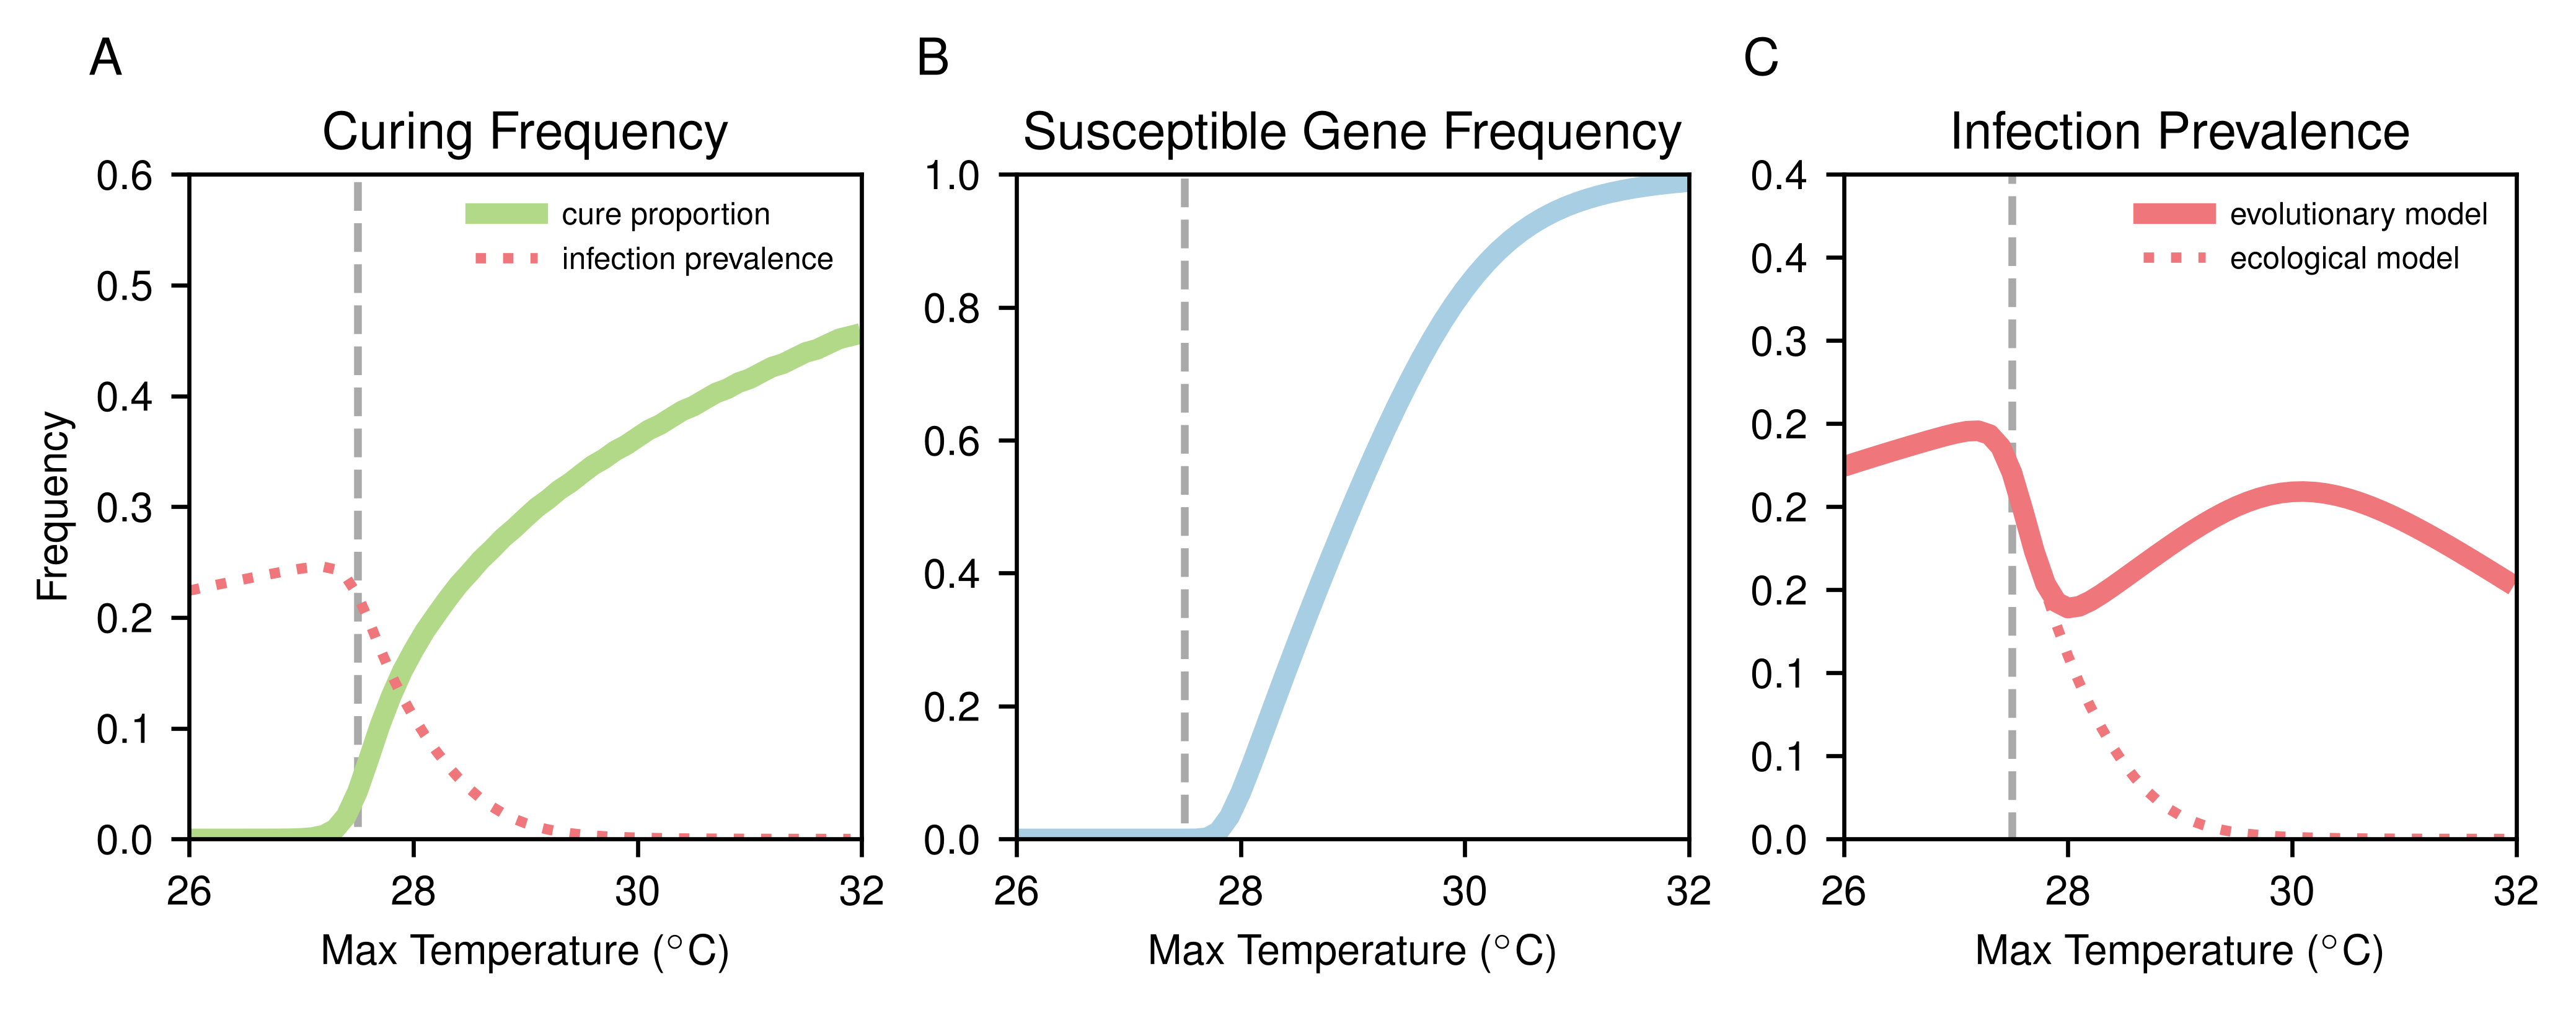

In [93]:
mm = 1/25.4
max_tempsfig, ax = plt.subplots(ncols=3, nrows=1, figsize=(173*mm, 66*mm), layout='constrained')

ax[0].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')
ax[1].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')
ax[2].vlines(27.5, ymin=-0.1, ymax=1.1, color='darkgrey', linestyle='dashed')

ax[0].tick_params(axis='both', which='major', labelsize=8)
ax[1].tick_params(axis='both', which='major', labelsize=8)
ax[2].tick_params(axis='both', which='major', labelsize=8)

ax[0].plot(max_temps, cure_freq, color=cure_color, linewidth=4, label='cure proportion')
ax[0].plot(max_temps, prev_eco, color=path_color, linestyle='dotted', linewidth=2, label='infection prevalence')

ax[1].plot(max_temps, sus_freq, color=host_color, linewidth=4)

ax[2].plot(max_temps, prev_evo, color=path_color, linewidth=4, label='evolutionary model')
ax[2].plot(max_temps, prev_eco, color=path_color, linestyle=':', linewidth=2, label='ecological model')

ax[0].set_title('Curing Frequency', pad=5, size=10)
ax[1].set_title('Susceptible Gene Frequency', pad=5, size=10)
ax[2].set_title('Infection Prevalence', pad=5, size=10)

ax[0].set_ylim(0, 0.6)
ax[1].set_ylim(0, 1)
ax[2].set_ylim(0, 0.4)

ax[0].set_xlim(26, 32)
ax[1].set_xlim(26, 32)
ax[2].set_xlim(26, 32)

ax[0].set_ylabel('Frequency', size=8)

for axis in ax.reshape(-1):
    axis.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.1f'))
    axis.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.0f'))

ax[0].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[1].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)
ax[2].set_xlabel(r'Max Temperature ($^\circ$C)', size=8)

ax[0].annotate("A", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[1].annotate("B", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)
ax[2].annotate("C", xy=(-0.15, 1.15), xycoords="axes fraction", fontsize=10)

ax[0].legend(frameon=False, fontsize=6, loc=1)
ax[2].legend(frameon=False, fontsize=6, loc=1)

In [20]:
def find_threshold(low, high, n_iter, count=0, sus=1.5, temp=27):
    if count == n_iter:
        return low

    else:
        mid = low + ((high - low) / 2)
        model = TempModel(temp_min=5, temp_max=temp, n_years=400, S1=450, S2=450, cost2=mid, res2=sus)
        model.solve()

        prop = (model.annual_mean('S2')[-1] + model.annual_mean('I2')[-1] + model.annual_mean('C2')[-1]) / (
            model.annual_mean('S1')[-1] + model.annual_mean('I1')[-1] + model.annual_mean('C1')[-1] +
            model.annual_mean('S2')[-1] + model.annual_mean('I2')[-1] + model.annual_mean('C2')[-1])

        if prop > 0.05:
            return(find_threshold(low, mid, n_iter, count=count+1, sus=sus, temp=temp))
        elif prop <= 0.05:
            return(find_threshold(mid, high, n_iter, count=count+1, sus=sus, temp=temp))

In [54]:
temp_vals = np.linspace(26, 30, 30)
sus_vals = [1.25, 1.5, 1.75, 2]
thresholds = np.zeros([len(sus_vals), len(temp_vals)])

n_sims = len(sus_vals)*len(temp_vals)

for i, sus in enumerate(sus_vals):
    for j, temp in enumerate(temp_vals):
        print((i*len(temp_vals)+j)/n_sims, end="\r")
        thresholds[i, j] = find_threshold(1, 1.4, 7, sus=sus, temp=temp)

In [ ]:
import pickle

with open('threshold.pkl', 'rb') as file:
    thresholds = pickle.load(file)

temp_vals = np.linspace(26, 30, 30)

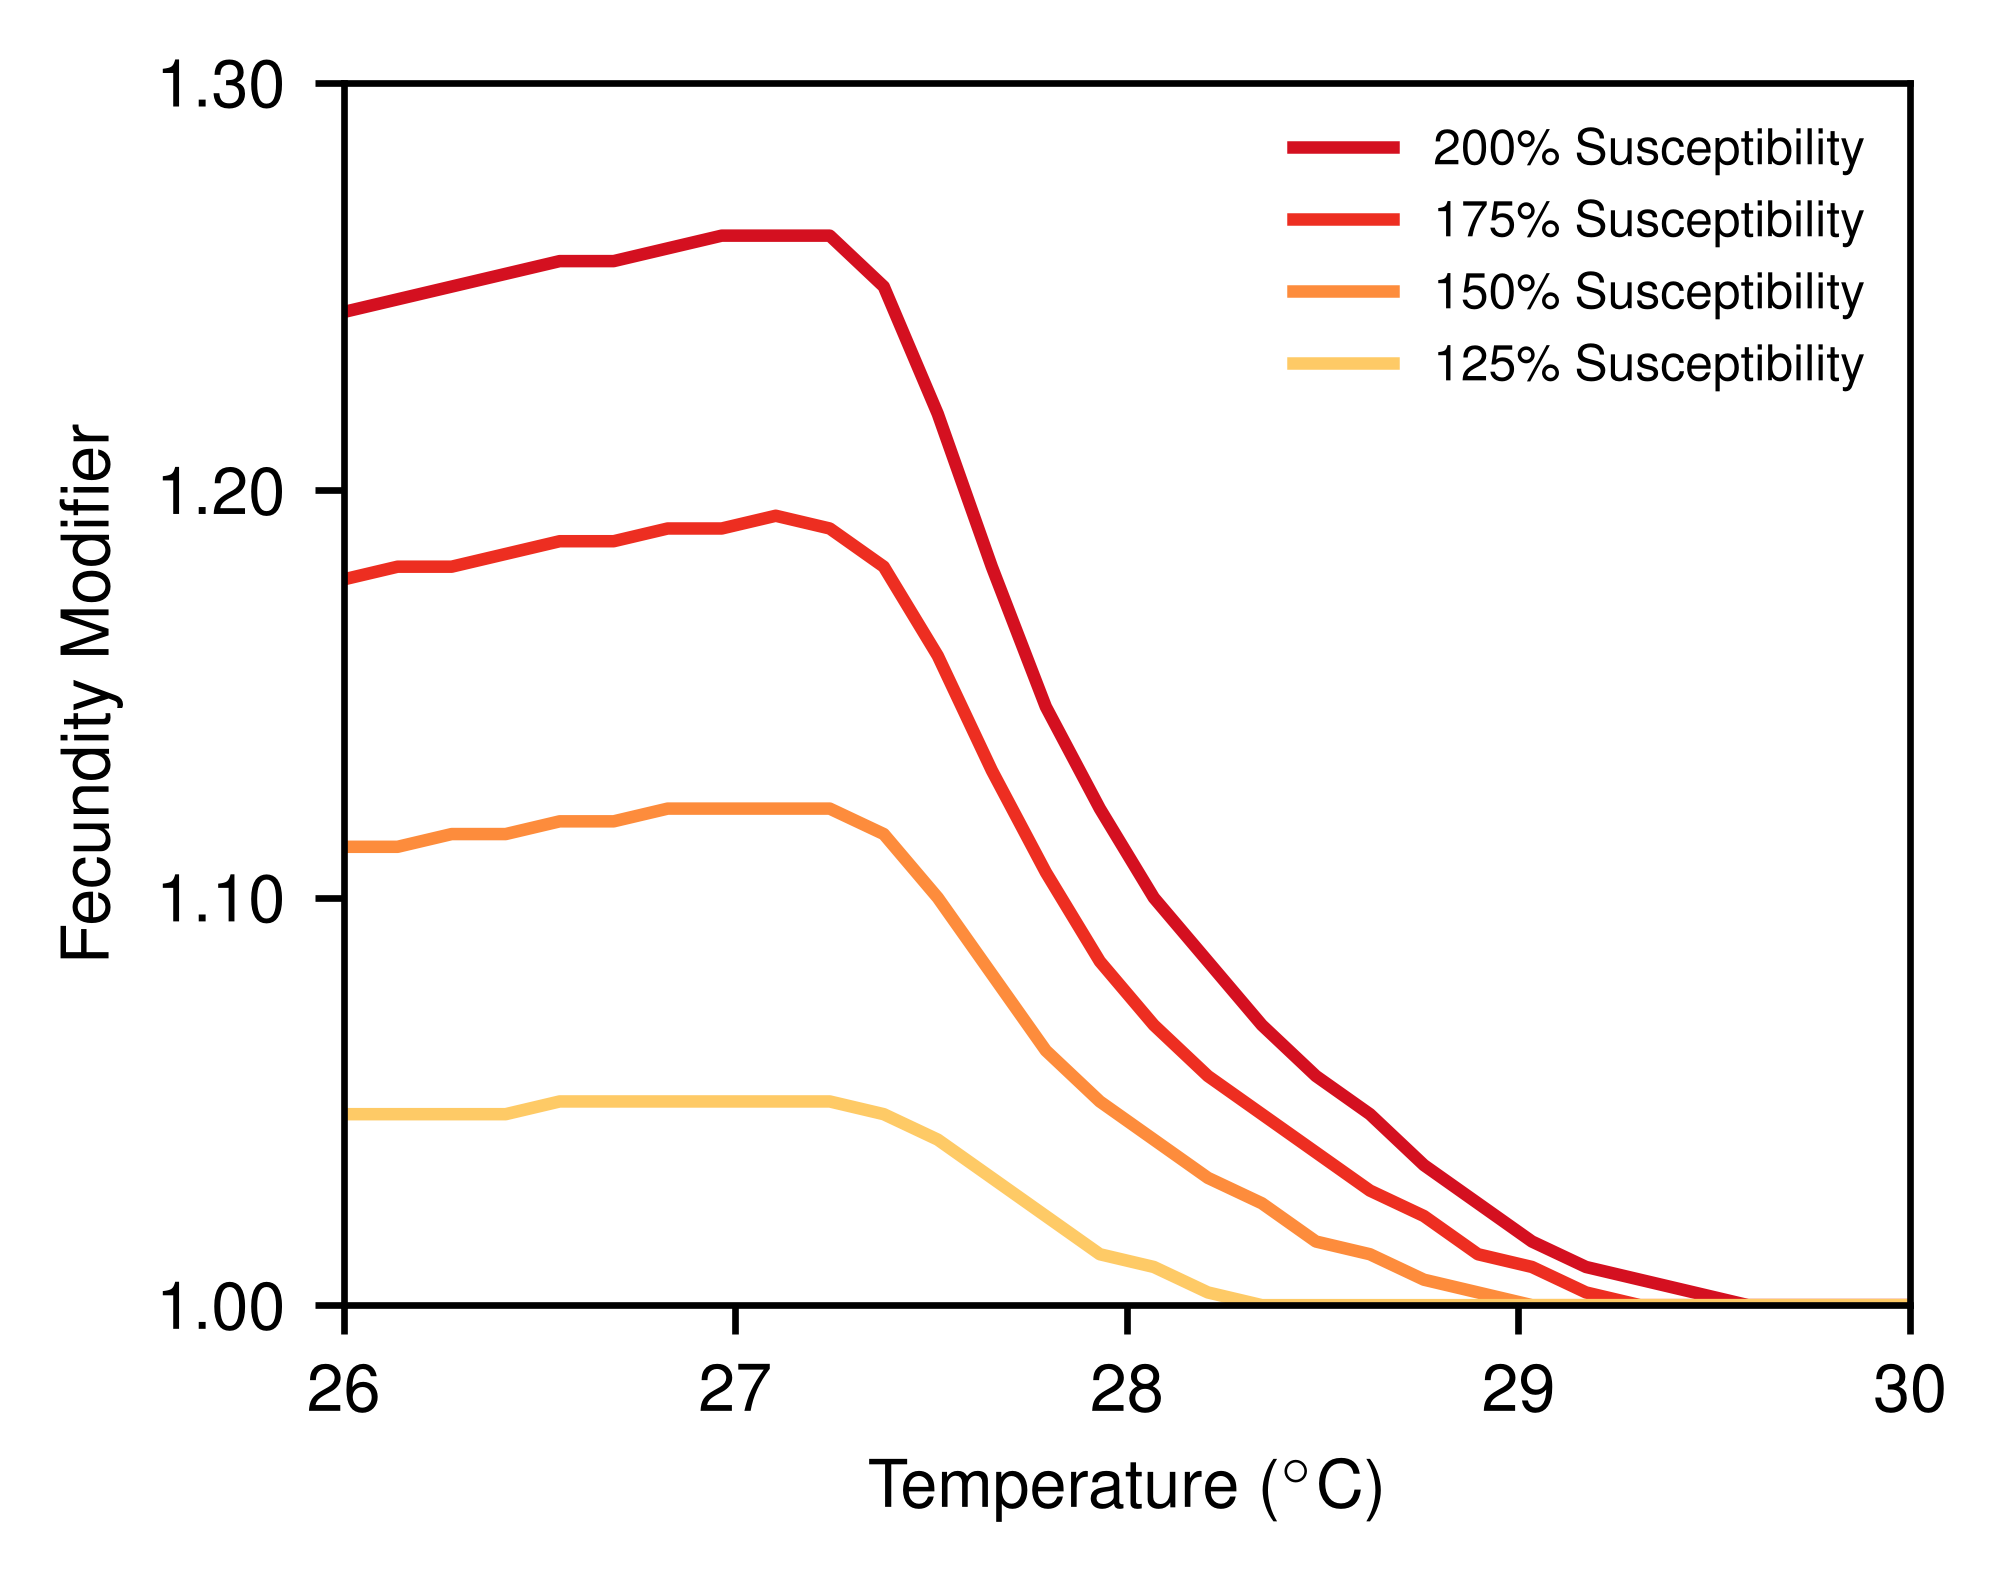

In [94]:
import matplotlib as mpl
mm = 1/25.4
max_tempsfig, ax = plt.subplots(ncols=1, nrows=1, figsize=(82*mm, 64*mm), layout='constrained')

cmap = mpl.colormaps['YlOrRd']

#ax.plot(temp_vals, thresholds[3, :], color=cmap(0.8), label=r'$\beta_2 = 2\beta_1$')
#ax.plot(temp_vals, thresholds[2, :], color=cmap(0.7), label=r'$\beta_2 = 1.75\beta_1$')
#ax.plot(temp_vals, thresholds[1, :], color=cmap(0.5), label=r'$\beta_2 = 1.5\beta_1$')
#ax.plot(temp_vals, thresholds[0, :], color=cmap(0.3), label=r'$\beta_2 = 1.25\beta_1$')

ax.plot(temp_vals, thresholds[3, :], color=cmap(0.8), label='200\\% Susceptibility')
ax.plot(temp_vals, thresholds[2, :], color=cmap(0.7), label='175\\% Susceptibility')
ax.plot(temp_vals, thresholds[1, :], color=cmap(0.5), label='150\\% Susceptibility')
ax.plot(temp_vals, thresholds[0, :], color=cmap(0.3), label='125\\% Susceptibility')

ax.tick_params(axis='both', which='major', labelsize=8)

ax.set_xlabel(r'Temperature ($^\circ$C)', fontsize=8)
ax.set_ylabel('Fecundity Modifier', fontsize=8)



ax.set_yticks((1, 1.1, 1.2, 1.3))

#ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=6))
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.2f'))
#ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=5))
ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.0f'))

ax.set_ylim(1, 1.3)
ax.set_xlim(26, 30)

ax.legend(frameon=False, fontsize=6)

In [91]:
import pickle

with open('threshold.pkl', 'wb') as file:
    pickle.dump(thresholds, file)